In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
# sklearn.set_config(display="text")

True

In [2]:

base_path = r"/Users/kdt_0900_lyn/ml/resoce/dataset/"
brain_path = os.path.join(base_path, "brain")

In [3]:

from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(brain_path, exist_ok=True)
# https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset/data
api.dataset_download_files(r"masoudnickparvar/brain-tumor-mri-dataset", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
다운로드 완료


In [63]:
train_path = os.path.join(base_path, "Training")
# val_path = os.path.join(base_path, "validation")
test_path = os.path.join(base_path, "Testing")



print(train_path, os.path.exists(train_path))
print(test_path, os.path.exists(test_path))

/Users/kdt_0900_lyn/ml/resoce/dataset/Training True
/Users/kdt_0900_lyn/ml/resoce/dataset/Testing True


In [31]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),  
    transforms.RandomHorizontalFlip(),  
    transforms.RandomRotation(15),      
    transforms.ToTensor(), 
    transforms.Normalize(mean=mean, std=std),
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
    
])

In [32]:
train_dataset = ImageFolder(train_path, transform=train_transform)

test_dataset = ImageFolder(test_path, transform=test_transform)

In [86]:
print(len(train_dataset), len(test_dataset))

5600 1600


### Path.mkdir(mode=0o777, parents=False, exist_ok=False, *, parent_mode=None)
- parents가 참이면, 이 경로의 누락 된 부모를 필요하면 만듭니다; 이것들은 mode를 고려하지 않고 기본 권한으로 만들어집니다
### PurePath.parent
- 경로의 논리적 부모:

In [ ]:
from 

In [64]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

In [35]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [36]:
model1 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

In [37]:
model1

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [38]:
for param in model1.parameters():
    param.requires_grad = False

In [39]:
model1.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(model1.classifier[1].in_features, 256),
    nn.BatchNorm1d(256), 
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 11)
)

In [40]:
model1 = model1.to(device)

In [41]:
model1

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [42]:
criterion = nn.CrossEntropyLoss()
optimizer1 = optim.Adam(model1.classifier.parameters(), lr=0.001)

In [43]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device="cpu"):
    model.train()
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [44]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [49]:
def train_model_multiclass(model, model_name, train_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "train_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================={model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================={model_name} 학습 종료 ============================")
    return history

In [50]:
criterion = nn.CrossEntropyLoss()
optimizer1 = optim.Adam(model1.classifier.parameters(), lr=0.001)

In [52]:
history1 = train_model_multiclass(
    model=model1,
    model_name="Mobilenet-multiclass",
    train_loader=train_dataloader,
    criterion=criterion,
    optimizer=optimizer1,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

=========================Mobilenet-multiclass 학습 시작 ============================
[Batch 20/88] Batch Loss: 0.6804, Batch Accuracy: 79.69%
[Batch 40/88] Batch Loss: 0.7454, Batch Accuracy: 75.00%
[Batch 60/88] Batch Loss: 0.4791, Batch Accuracy: 84.38%
[Batch 80/88] Batch Loss: 0.5594, Batch Accuracy: 75.00%
[Epoch: 1] | Train Loss: 0.7511 | Train Accuracy: 74.34%
[Batch 20/88] Batch Loss: 0.5650, Batch Accuracy: 79.69%
[Batch 40/88] Batch Loss: 0.5416, Batch Accuracy: 78.12%
[Batch 60/88] Batch Loss: 0.5334, Batch Accuracy: 81.25%
[Batch 80/88] Batch Loss: 0.4868, Batch Accuracy: 79.69%
[Epoch: 2] | Train Loss: 0.5121 | Train Accuracy: 80.33%
[Batch 20/88] Batch Loss: 0.6609, Batch Accuracy: 78.12%
[Batch 40/88] Batch Loss: 0.4719, Batch Accuracy: 84.38%
[Batch 60/88] Batch Loss: 0.2979, Batch Accuracy: 87.50%
[Batch 80/88] Batch Loss: 0.3699, Batch Accuracy: 84.38%
[Epoch: 3] | Train Loss: 0.4995 | Train Accuracy: 80.97%
[Batch 20/88] Batch Loss: 0.5226, Batch Accuracy: 76.56%
[Batch 

In [83]:
best_model_path = os.path.join(base_path, r"weights_brain", r"Mobilenet-multiclass", r"best_model.pth")
best_model_path    

'/Users/kdt_0900_lyn/ml/resoce/dataset/weights_brain/Mobilenet-multiclass/best_model.pth'

In [ ]:
from pathlib import Path

# 저장할 폴더 만들기
Path(best_model_path).parent.mkdir(parents=True, exist_ok=True)

# 현재 모델 저장
torch.save(model1.state_dict(), best_model_path)

# 저장한 모델 불러오기
model1.load_state_dict(torch.load(best_model_path))
model1 = model1.to(device)

In [71]:
model1.load_state_dict(torch.load(best_model_path))

model1 = model1.to(device)


In [72]:
model1.eval()

# 최종 test_dataloader로 평가
test_loss, test_acc = evaluate_multiclass(
    model=model1, 
    dataloader=test_dataloader,
    criterion=criterion, 
    device=device
)

print(f"최종 모델의 평가")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

최종 모델의 평가
Test Loss: 0.5034
Test Accuracy: 83.19%


In [87]:
imgs, labels = next(iter(test_dataloader))

In [88]:
class_to_idx = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))

In [89]:
imgs, labels = next(iter(test_dataloader))

In [90]:
class_to_idx = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))

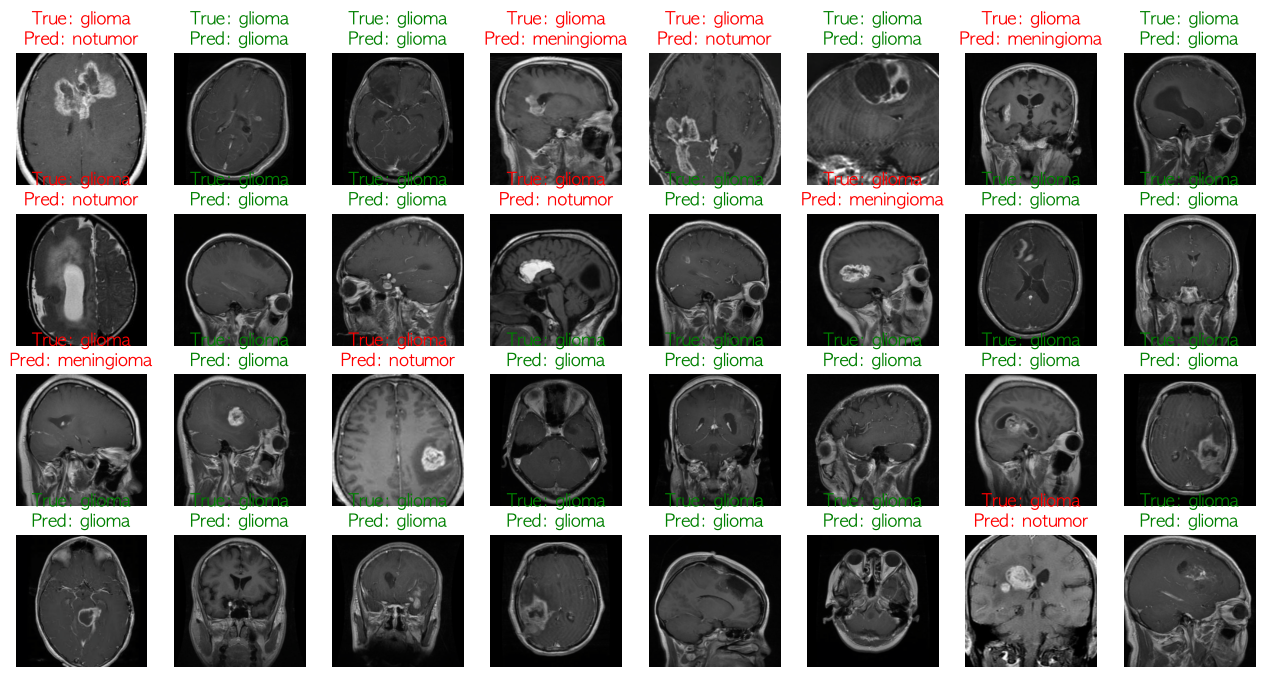

In [77]:
model1.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

mean = np.array(mean)
std = np.array(std)

for ax, img, label, pred in zip(axes.flatten(), imgs, labels, pred_labels):
    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)
    true_label = int(label.item())
    pred_label = int(pred.item())
    color = "green" if true_label == pred_label else "red"
    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[true_label]}\nPred: {class_dict[pred_label]}", color=color)
    ax.axis("off")

plt.show()

In [78]:
model1.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

incorrect_samples = []
incorrect_mask = (pred_labels != labels)

if incorrect_mask.any():
    for img, label, pred in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask]):
        incorrect_samples.append({
            "img": img,
            "true_label": label.item(),
            "pred_label": pred.item()
        })

print(incorrect_samples)

[{'img': tensor([[[-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         ...,
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179]],

        [[-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         ...,
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357]],

        [[-1.8044, -1.8044, -1.8044,  ..., -1.8044, -1.8044, -1.8044],
         [-1.8044, -1.8044, -1.8044,